# 1. AG News: Data Acquisition, Exploration and Cleaning

We use the AG News topic classification corpus (Zhang et al., 2015), which contains 120,000 training and 7,600 test articles evenly distributed over four classes: World, Sports, Business and Sci/Tech. Each record concatenates the headline and the short description of a news article.

This notebook downloads the official splits, inspects the class balance and text length, and documents the normalisation applied before modelling.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

## 1.1 Download and preprocess

In [2]:
from src import config
from src.download_data import download
from src.preprocess import preprocess_and_save

if not (config.RAW_DIR / "ag_news_train.csv").exists():
    download()
preprocess_and_save()

train: 108,000 rows -> data\processed\ag_news_clean_train.csv
val: 12,000 rows -> data\processed\ag_news_clean_val.csv
test: 7,600 rows -> data\processed\ag_news_clean_test.csv


In [3]:
import pandas as pd

raw_train = pd.read_csv(config.RAW_DIR / "ag_news_train.csv")
splits = {s: pd.read_csv(config.PROCESSED_DIR / f"ag_news_clean_{s}.csv") for s in ("train", "val", "test")}
pd.DataFrame({s: [len(d)] for s, d in splits.items()}, index=["articles"])

,train,val,test
articles,108000,12000,7600


## 1.2 Class distribution

The corpus is balanced by construction, and the stratified validation split preserves that balance.

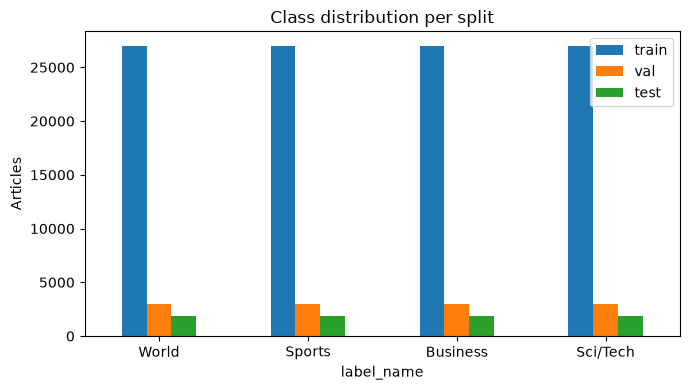

,train,val,test
label_name,,,
World,27000,3000,1900
Sports,27000,3000,1900
Business,27000,3000,1900
Sci/Tech,27000,3000,1900


In [4]:
import matplotlib.pyplot as plt

counts = pd.DataFrame({s: d["label_name"].value_counts() for s, d in splits.items()}).loc[config.LABEL_NAMES]
ax = counts.plot.bar(figsize=(7, 4), rot=0)
ax.set_ylabel("Articles")
ax.set_title("Class distribution per split")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "class_distribution.png", dpi=300)
plt.show()
counts

## 1.3 Article length

Articles are short. Their length in words informs the maximum sequence length used for BERT (128 sub-word tokens).

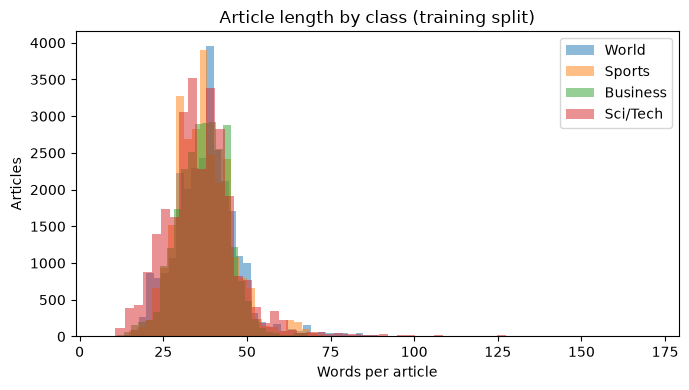

,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
Business,27000.0,37.2,8.0,7.0,32.0,37.0,42.0,134.0
Sci/Tech,27000.0,36.7,12.6,8.0,30.0,36.0,42.0,171.0
Sports,27000.0,37.3,8.8,10.0,31.0,36.0,42.0,151.0
World,27000.0,38.2,10.2,11.0,32.0,38.0,43.0,145.0


In [5]:
train = splits["train"]
train["n_words"] = train["text"].str.split().str.len()

fig, ax = plt.subplots(figsize=(7, 4))
for name in config.LABEL_NAMES:
    ax.hist(train.loc[train["label_name"] == name, "n_words"], bins=60, alpha=0.5, label=name)
ax.set_xlabel("Words per article")
ax.set_ylabel("Articles")
ax.set_title("Article length by class (training split)")
ax.legend()
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "text_length_distribution.png", dpi=300)
plt.show()
train.groupby("label_name")["n_words"].describe().round(1)

## 1.4 Text normalisation

The raw descriptions contain escaped HTML entities (for example `#39;` and `quot;`) and news-agency bylines such as `(Reuters)` or `AFP -`. Bylines identify the source rather than the topic, so a classifier could exploit them as shortcuts. We remove both before modelling and keep two views of each article:

* `text`: entities and bylines removed, casing and punctuation preserved (input to BERT);
* `clean_text`: additionally lower-cased and restricted to alphabetic tokens (input to TF-IDF).

In [6]:
from src.preprocess import clean_text

pd.set_option("display.max_colwidth", 200)
sample = raw_train.sample(5, random_state=config.SEED)
pd.DataFrame({"raw": sample["text"].values, "clean_text": sample["text"].map(clean_text).values})

,raw,clean_text
0,"BBC set for major shake-up, claims newspaper London - The British Broadcasting Corporation, the world #39;s biggest public broadcaster, is to cut almost a quarter of its 28 000-strong workforce, i...",bbc set for major shake up claims newspaper london the british broadcasting corporation the world s biggest public broadcaster is to cut almost a quarter of its strong workforce in the biggest sha...
1,Marsh averts cash crunch Embattled insurance broker #39;s banks agree to waive clause that may have prevented access to credit. NEW YORK (Reuters) - Marsh amp; McLennan Cos.,marsh averts cash crunch embattled insurance broker s banks agree to waive clause that may have prevented access to credit new york marsh mclennan cos
2,"Jeter, Yankees Look to Take Control (AP) AP - Derek Jeter turned a season that started with a terrible slump into one of the best in his accomplished 10-year career.",jeter yankees look to take control derek jeter turned a season that started with a terrible slump into one of the best in his accomplished year career
3,"Flying the Sun to Safety When the Genesis capsule comes back to Earth with its samples of the sun, helicopter pilots will be waiting for it, ready to snag it out of the sky.",flying the sun to safety when the genesis capsule comes back to earth with its samples of the sun helicopter pilots will be waiting for it ready to snag it out of the sky
4,Stocks Seen Flat as Nortel and Oil Weigh NEW YORK (Reuters) - U.S. stocks were set to open near unchanged on Thursday after a warning from technology bellwether Nortel Networks Corp. &lt;A HREF...,stocks seen flat as nortel and oil weigh new york u s stocks were set to open near unchanged on thursday after a warning from technology bellwether nortel networks corp nt n dimmed hopes while stu...


In [7]:
agency = raw_train["text"].str.contains(r"\((?:AP|AFP|Reuters)\)|\b(?:AP|AFP|Reuters) - ", regex=True)
print(f"Articles containing an agency byline before cleaning: {agency.mean():.1%}")

Articles containing an agency byline before cleaning: 19.7%
